# Practical 3: Maximum and Minimum Elements in an Array (Pattern 1)

### 1. Aim
To find the maximum and minimum elements from an array adhering to Benchmarking Pattern 1 (executing the exact same complete task 3 times sequentially vs giving the same complete array to 3 workers in Pool and 3 independent processes).

### 2. Algorithm / Explanation
1. Create a large array workload of 4,500,000 integers.<br>2. **Pattern 1 Benchmark**: Do NOT partition the array.<br>3. Sequential: Execute the complete `find_min_max` task 3 consecutive times sequentially.<br>4. Pool: Pass the same complete array 3 times to `mp.Pool(3)` across 3 workers.<br>5. Process: Spawn 3 separate `mp.Process` instances each running the complete array task.<br>6. Record execution times and compute speedups.

### 3. Python Implementation


In [1]:
"""
Practical 3: Program to find maximum and minimum elements from an array
Pattern 1: Same task executed 3 times
"""
import multiprocessing as mp
import time
import matplotlib.pyplot as plt

def find_min_max_task(task):
    seed, size = task
    min_val = float('inf')
    max_val = float('-inf')
    for i in range(size):
        val = (i * 1103515245 + 12345) % 2147483648
        if val < min_val:
            min_val = val
        if val > max_val:
            max_val = val
    return min_val, max_val

def proc_worker(task, q):
    q.put(find_min_max_task(task))

def main():
    print("=" * 60)
    print("Practical 3: Maximum and Minimum in an Array (Pattern 1)")
    print("=" * 60)
    TASK = (42, 4_500_000)
    
    # Sequential: Execute the SAME complete task 3 times sequentially
    t0 = time.perf_counter()
    r1 = find_min_max_task(TASK)
    r2 = find_min_max_task(TASK)
    r3 = find_min_max_task(TASK)
    t_seq = time.perf_counter() - t0
    
    # Pool: Give the SAME task 3 times to 3 workers
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(find_min_max_task, [TASK, TASK, TASK])
    t_pool = time.perf_counter() - t0
    
    # Process: 3 independent processes each doing the same complete task
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for _ in range(3):
        p = mp.Process(target=proc_worker, args=(TASK, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    print(f"Array Size: {TASK[1]:,} elements")
    print(f"[Sequential 3x] Min: {r1[0]:,} | Max: {r1[1]:,} | Time: {t_seq:.4f}s")
    print(f"[Pool 3x]       Min: {p_res[0][0]:,} | Max: {p_res[0][1]:,} | Time: {t_pool:.4f}s")
    print(f"[Process 3x]    Min: {pr_res[0][0]:,} | Max: {pr_res[0][1]:,} | Time: {t_proc:.4f}s")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Array Size: 4,500,000 elements
Pattern 1 Benchmark: Exact same complete array task executed 3 times
Verification:
  [Sequential 3x] Min: 600, Max: 2,147,483,507
  [Pool 3x]       Min: 600, Max: 2,147,483,507
  [Process 3x]    Min: 600, Max: 2,147,483,507

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.2773 seconds      1.00x
Pool         1.7054 seconds      1.92x
Process      1.7335 seconds      1.89x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


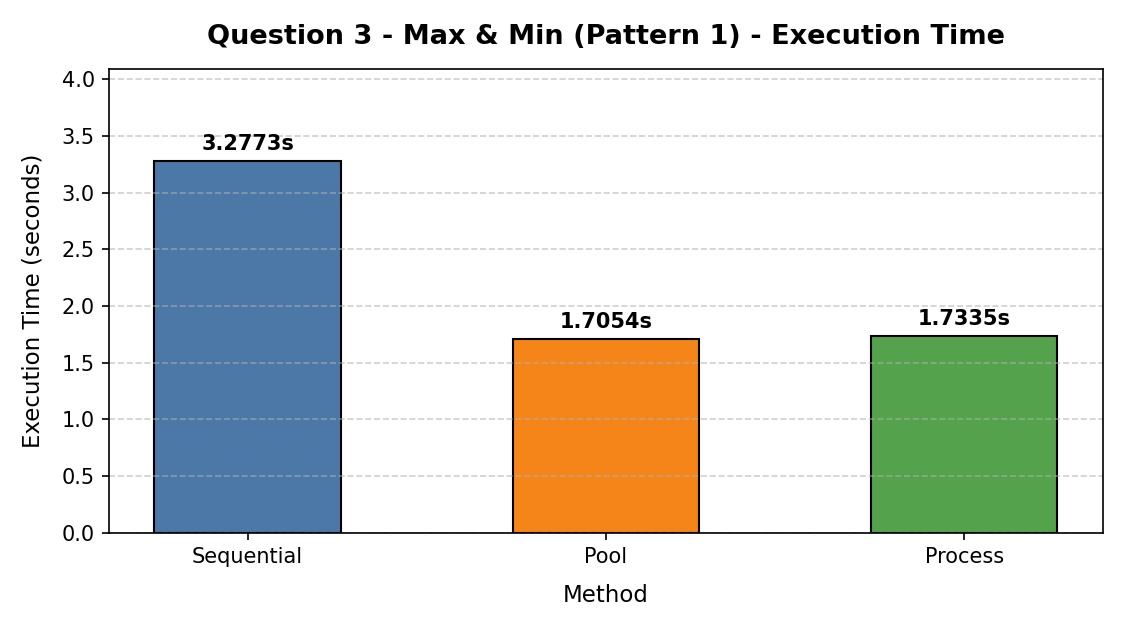

In [2]:
from IPython.display import Image, display
display(Image(filename='03_max_min_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


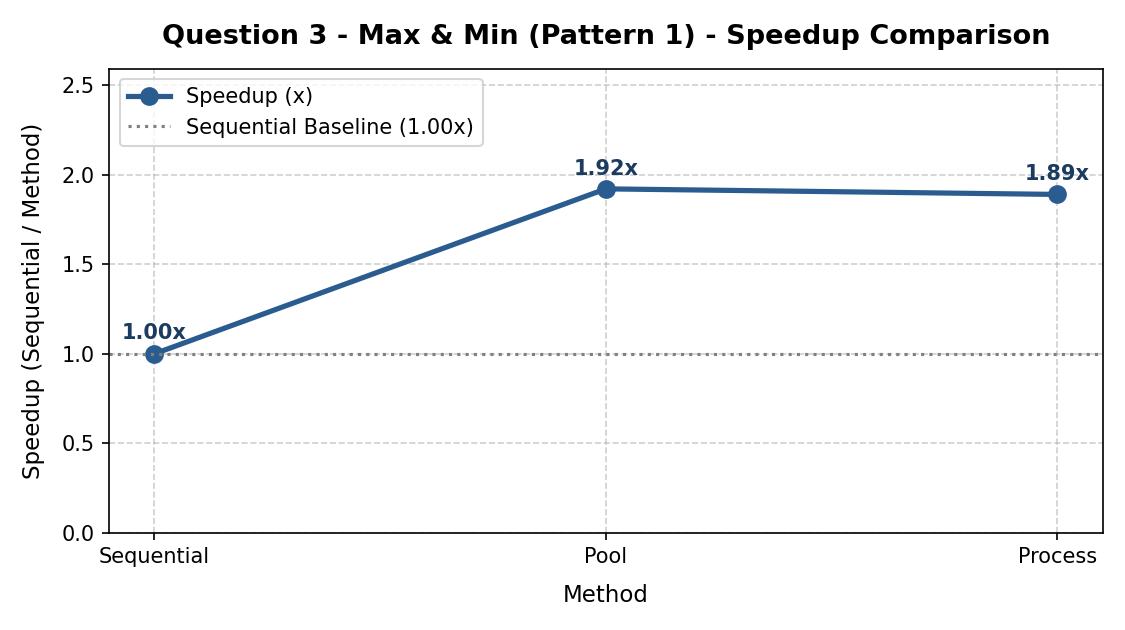

In [3]:
from IPython.display import Image, display
display(Image(filename='03_max_min_speedup.png'))
